Шаг 1. Создание таблиц customers, products, orders и order_items.

In [ ]:
# Таблица customers(информация о клиентах)

CREATE TABLE public.customers_hw01 (
	customer_id int4 NULL,
	first_name varchar(50) NULL,
	last_name varchar(50) NULL,
	gender varchar(50) NULL,
	dob varchar(50) NULL,
	job_title varchar(50) NULL,
	job_industry_category varchar(50) NULL,
	wealth_segment varchar(50) NULL,
	deceased_indicator bool NULL,
	owns_car bool NULL,
	address varchar(50) NULL,
	postcode int4 NULL,
	state varchar(50) NULL,
	country varchar(50) NULL,
	property_valuation float4 NULL
);

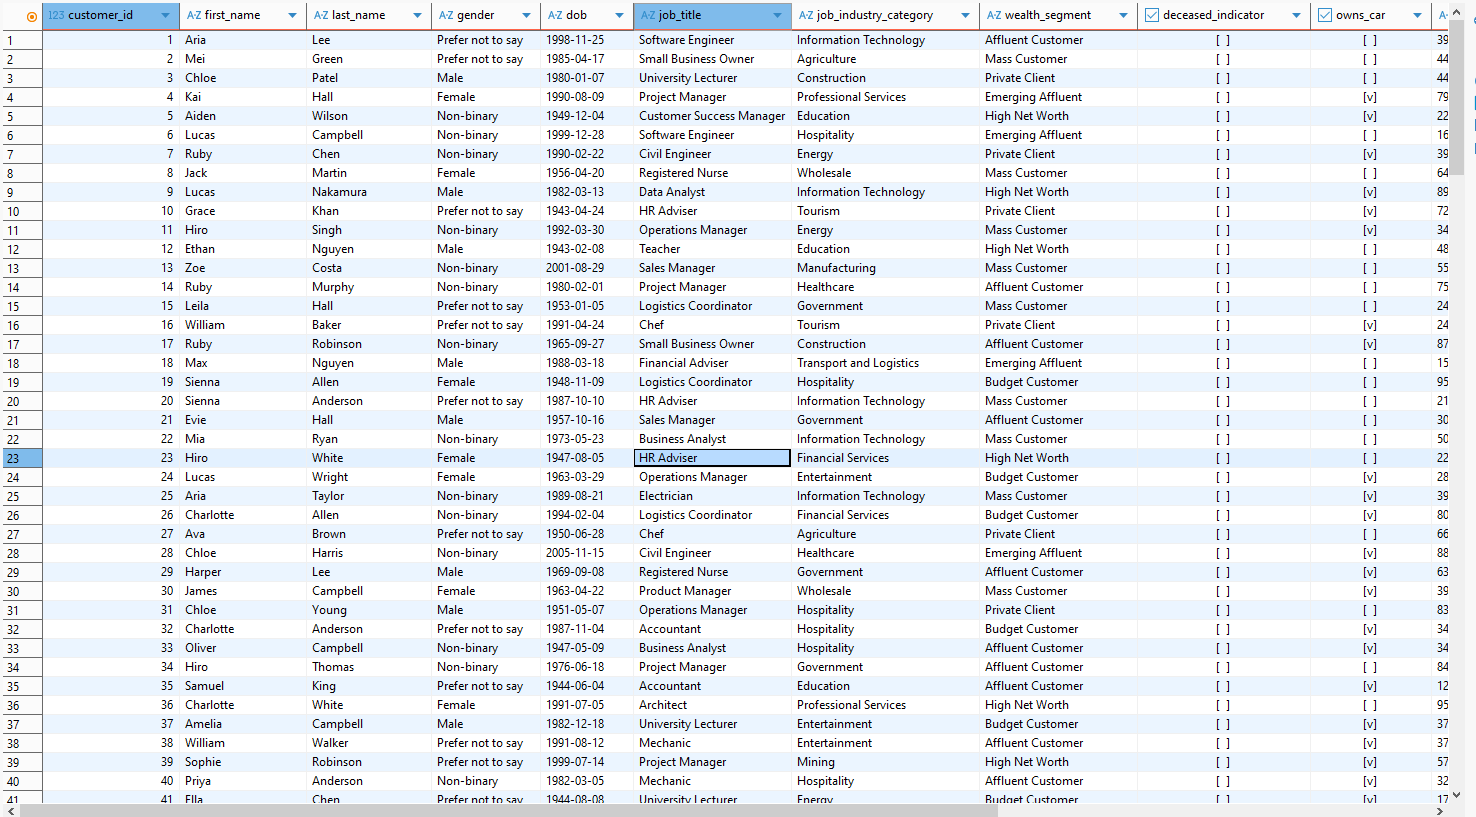

In [ ]:
# Таблица products(каталог продуктов)

CREATE TABLE public.products_hw01 (
	product_id int4 NULL,
	brand varchar(50) NULL,
	product_line varchar(50) NULL,
	product_class varchar(50) NULL,
	product_size varchar(50) NULL,
	list_price float4 NULL,
	standard_cost float4 NULL
);

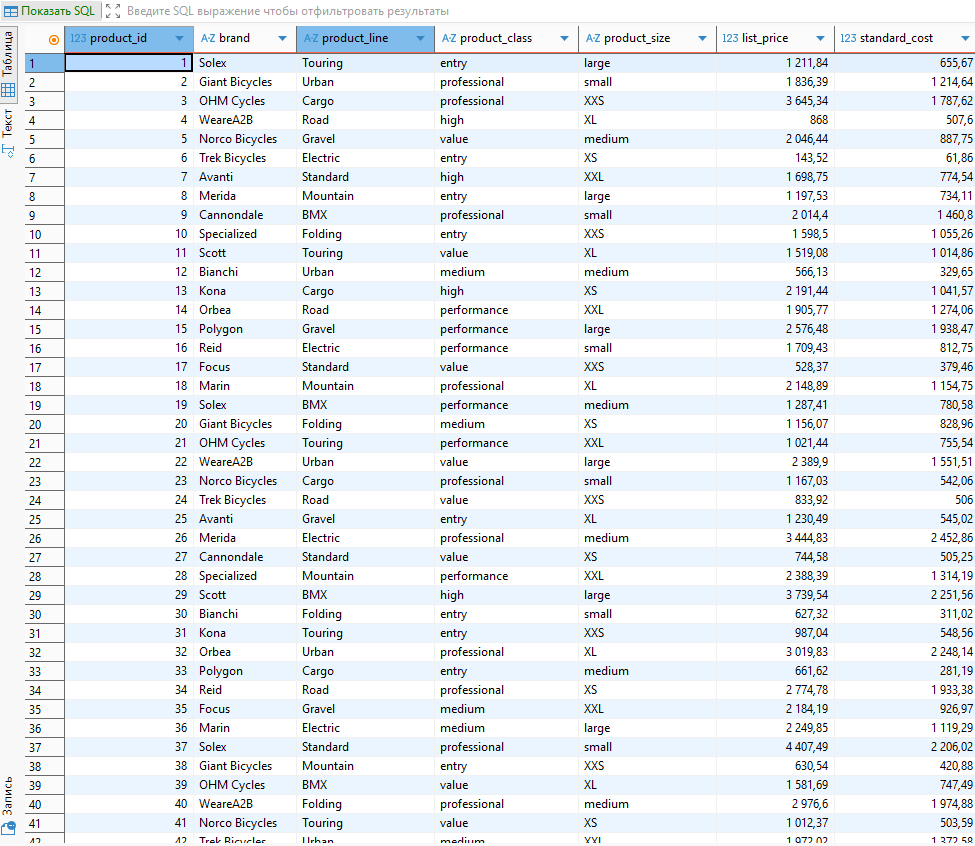

In [ ]:
# Таблица orders(заказы клиентов)

CREATE TABLE public.orders_hw01 (
	order_id int4 NULL,
	customer_id int4 NULL,
	order_date varchar(50) NULL,
	online_order bool NULL,
	order_status varchar(50) NULL
);

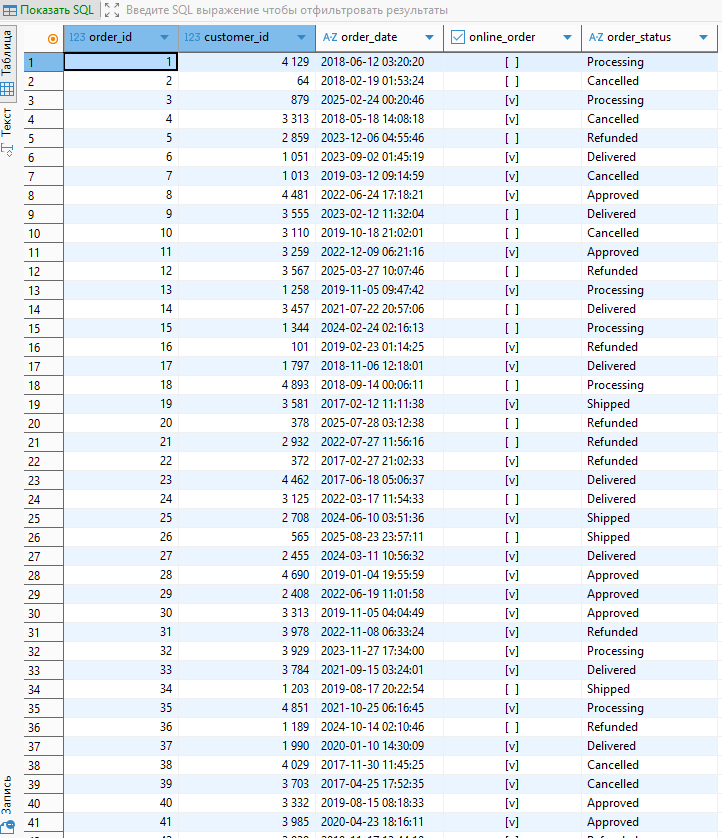

In [ ]:
# Таблица order_items(позиции в заказах)

CREATE TABLE public.order_items_hw01 (
	order_item_id int4 NULL,
	order_id int4 NULL,
	product_id int4 NULL,
	quantity int4 NULL,
	item_list_price_at_sale float4 NULL,
	item_standard_cost_at_sale float4 NULL
);

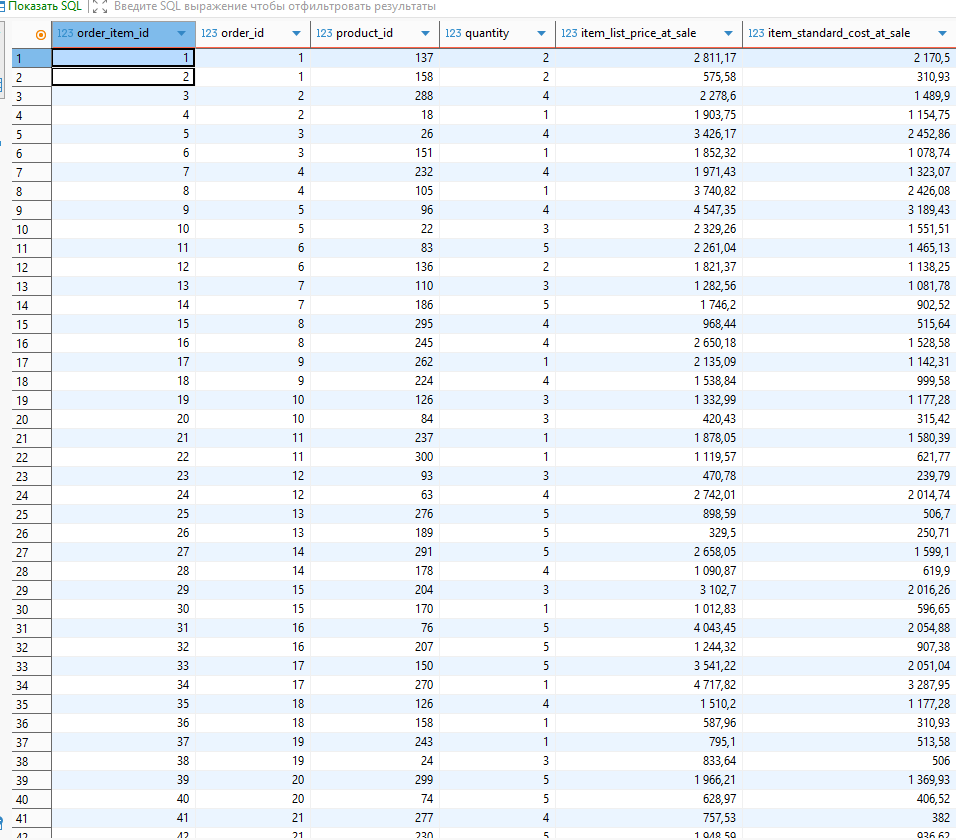

Шаг 2. Анализ данных

2.1 Первичные ключи:
    -  Для таблицы customers в качестве PRIMARY KEY назначен столбец customer_id;
    -  Для таблицы products в качестве PRIMARY KEY назначен столбец product_id;
    -  Для таблицы orders в качестве PRIMARY KEY назначен столбец customer_id;
    -  Для таблицы order_items в качестве PRIMARY KEY назначен столбец order_item_id.

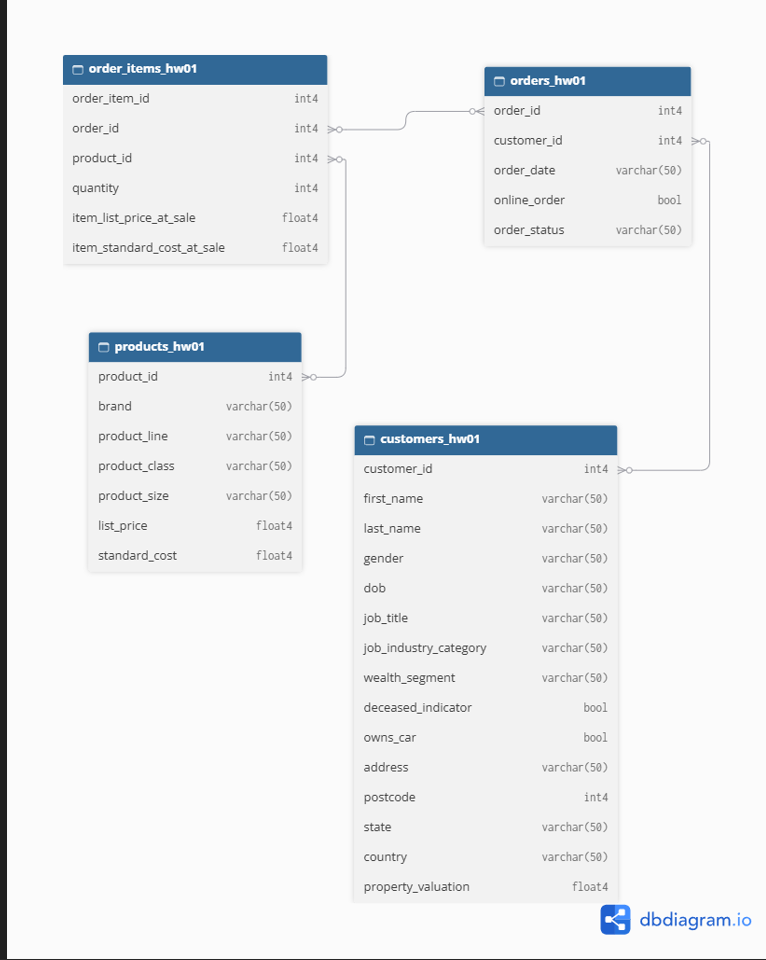

2.2 Проверка нормализации.

| Таблица | 1НФ | 2НФ | 3НФ |
|-----------|-----------|-----------|-----------|
| Customers  | +  | +  | ?  |
| Products  | +  | +  | ?  |
| Orders  | + | + | ? |
| Order_items | +| + | ? |


2.3 Проверка дублей по ключам

| Наименование таблицы | PK/FK | Выявленные дубли | Способ дедубликации | Итоговое количество строк |
|-----------|-----------|-----------|-----------|-----------|
| Customers  | customer_id/-  |  -  | -  | 5000  |
| Products  | product_id/-  |  -  | -  | 300 |
| Orders | order_id/- | - | - | 25000 |
| Order_items 16 | order_item_id/order_id, product_id | - | - | 50000 |

Шаг 3. Выполнение запросов

In [ ]:
# 3.1 Выведите id продукта и среднюю цену продажи (item_list_price_at_sale) для 5 продуктов с самой высокой средней ценой продажи.

select product_id, AVG(item_list_price_at_sale) as avg_item_list_price_at_sale
FROM order_items_hw01
group by product_id
ORDER BY avg_item_list_price_at_sale desc
LIMIT 5;

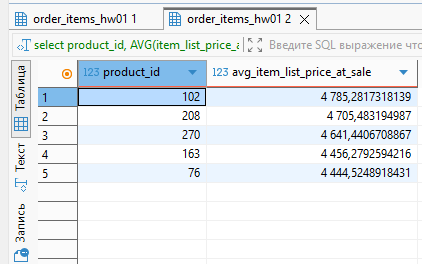

In [ ]:
# 3.2 Рассчитайте общую стоимость заказа (item_list_price_at_sale * quantity) для каждого бренда продукта.

select t2.brand, sum(t1.quantity * t1.item_list_price_at_sale) as p_brand
from order_items_hw01 as t1
left join products_hw01 as t2
on t1.product_id=t2.product_id
group by t2.brand
order by p_brand
desc 

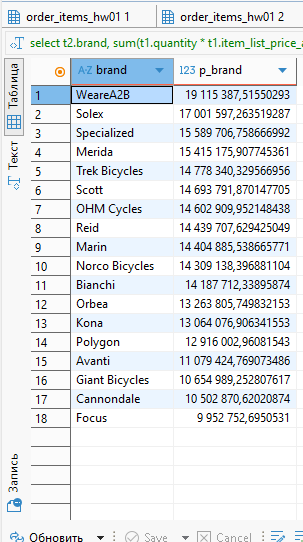

In [ ]:
# 3.3 Подсчитайте количество заказов за каждый месяц для каждого года. То есть необходимо вывести год, месяц и количество заказов.

SELECT
    EXTRACT(YEAR  FROM order_date::date) AS year_date,
    EXTRACT(MONTH FROM order_date::date) AS month_date,
    COUNT(order_id) AS order_count
FROM orders_hw01
GROUP BY 1, 2
ORDER BY 1, 2

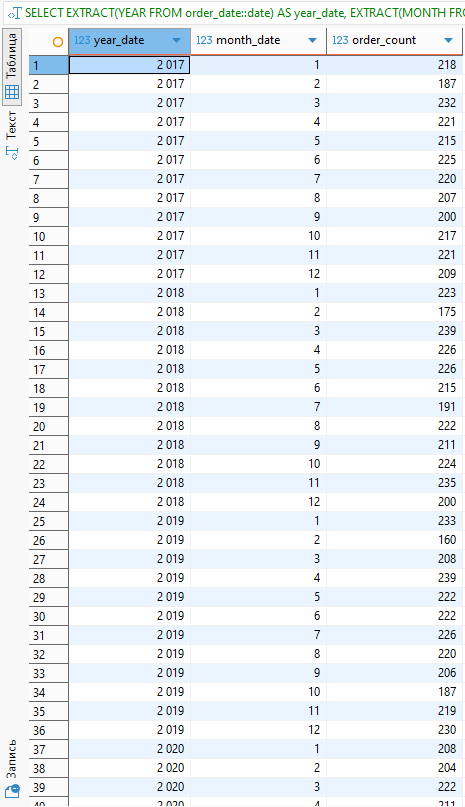

In [ ]:
# 3.4 Для каждой продуктовой линейки (product_line) найдите продукт с самой высокой стандартной стоимостью (standard_cost). Выведите id продукта, линейку продукта и стандартную стоимость. 
Также можно сделать через оконную функцию или специальную постгре команду distinct on

SELECT t1.product_id, t1.product_line, t1.standard_cost
FROM products_hw01 as t1
WHERE t1.standard_cost = (
    SELECT MAX(t2.standard_cost)
    FROM products_hw01 t2
    WHERE t2.product_line = t1.product_line
)

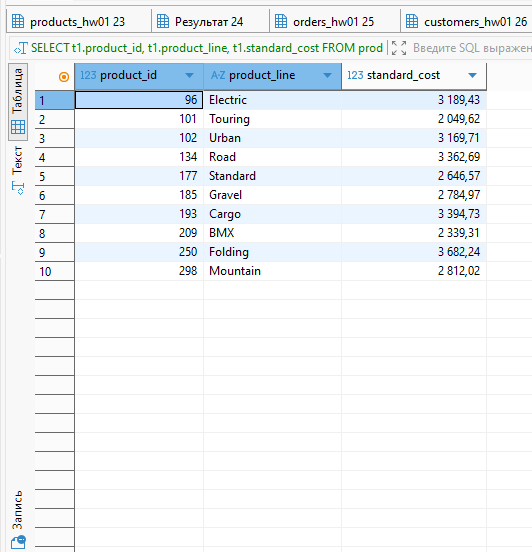

In [ ]:
# 3.5 Подсчитайте количество заказов и общую стоимость заказов для каждого статуса заказа (order_status). Общую стоимость заказа необходимо рассчитать как цену продукта на момент продажи, умноженную на количество единиц продукта в заказе.

select t1.order_status, count(distinct t1.order_id) as count_orders, sum(t2.quantity * t2.item_list_price_at_sale) as total_cost
from orders_hw01 as t1
left join order_items_hw01 as t2
on t1.order_id=t2.order_id
group by t1.order_status


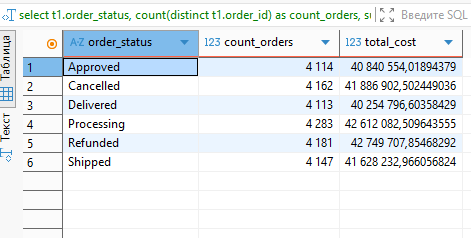

In [ ]:
# 3.6 Найдите клиентов, у которых нет ни одного заказа. Выведите id клиента, фамилию и имя.

select c.customer_id, c.last_name, c.first_name
from customers_hw01 c
left join orders_hw01 orders on c.customer_id=orders.customer_id
WHERE orders.order_id IS NULL

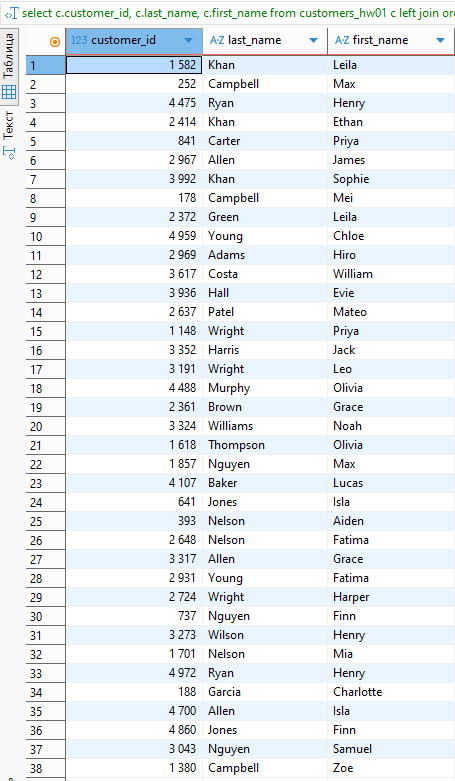

In [ ]:
# 3.7 Для каждого штата найдите клиента с самой высокой и самой низкой оценкой стоимости имущества (property_valuation). Выведите штат, оценку стоимости имущества, фамилию и имя клиента.

SELECT t.state, t.property_valuation, t.last_name, t.first_name
FROM (
    SELECT
        state,
        property_valuation,
        last_name,
        first_name,
        RANK() OVER (PARTITION BY state ORDER BY property_valuation DESC) AS rn_max,
        RANK() OVER (PARTITION BY state ORDER BY property_valuation ASC)  AS rn_min
    FROM customers_hw01
) t
WHERE t.rn_max = 1 OR t.rn_min = 1
ORDER BY t.state, t.property_valuation desc

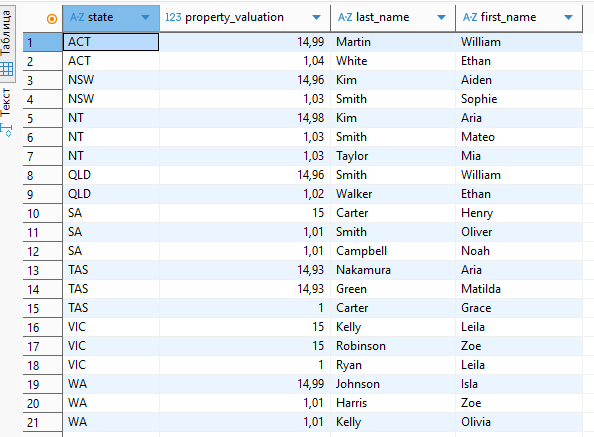

In [ ]:
# 3.8 Найдите клиентов, которые покупали продукты только из одной продуктовой линейки (product_line). Выведите id клиента, линейку продукта и количество заказов.

WITH cust_lines AS (
    SELECT
        t1.customer_id,
        COUNT(DISTINCT t3.product_line) AS lines_cnt
    FROM orders_hw01 t1
    JOIN order_items_hw01 t2 ON t2.order_id = t1.order_id
    JOIN products_hw01 t3 ON t3.product_id = t2.product_id
    GROUP BY t1.customer_id
)
SELECT
    cl.customer_id,
    products.product_line,
    COUNT(DISTINCT orders.order_id) AS orders_count
FROM cust_lines cl
JOIN orders_hw01 orders ON orders.customer_id = cl.customer_id
JOIN order_items_hw01 oi ON oi.order_id = orders.order_id
JOIN products_hw01 products ON products.product_id = oi.product_id
WHERE cl.lines_cnt = 1
GROUP BY cl.customer_id, products.product_line
ORDER BY cl.customer_id

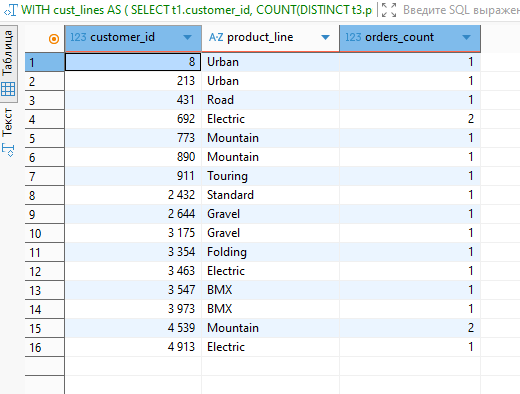

In [ ]:
# 3.9 select products.product_class, 
	ROUND(100.0 * COUNT(DISTINCT CASE WHEN orders.order_status = 'Cancelled' THEN orders.order_id END) / COUNT(DISTINCT orders.order_id), 2) AS percent_cancelled
from products_hw01 products 
join order_items_hw01 oi on products.product_id = oi.product_id
join orders_hw01 orders on orders.order_id = oi.order_id
group by products.product_class

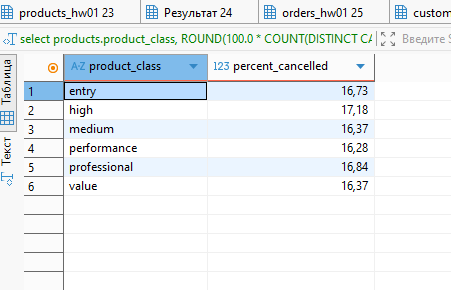

In [ ]:
# 3.10 Разделите клиентов на сегменты на основе количества заказов и подсчитайте количество клиентов в каждом сегменте:
-- сегмент High, если количество заказов больше 10;
-- сегмент Medium, если количество заказов от 5 до 10;
-- иначе сегмент Low.

WITH customer_orders AS (
    SELECT
        customer_id,
        COUNT(DISTINCT order_id) AS total_orders
    FROM orders_hw01
    GROUP BY customer_id
)
SELECT
    CASE
        WHEN total_orders > 10 THEN 'High'
        WHEN total_orders BETWEEN 5 AND 10 THEN 'Medium'
        ELSE 'Low'
    END AS segment,
    COUNT(*) AS customers_count
FROM customer_orders
GROUP BY segment

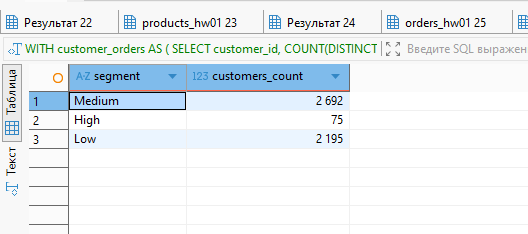

In [ ]:
# 3.11 Для всех клиентов выведите имена, фамилии, профессии, а также длительность максимального интервала (в днях) между двумя последовательными заказами. Необходимо исключить клиентов, у которых только один заказ или меньше.

with order_lags as (
    select
        orders.customer_id,
        orders.order_date::date - LAG(orders.order_date::date) OVER (
            PARTITION BY orders.customer_id
            ORDER BY orders.order_date::date
        ) as lag_days
    from orders_hw01 orders
)
select
	cl.customer_id,
    cl.first_name,
    cl.last_name,
    cl.job_title,
    MAX(lags.lag_days) AS max_lag_days
from order_lags lags
join customers_hw01 cl ON cl.customer_id = lags.customer_id
group by cl.customer_id, cl.first_name, cl.last_name, cl.job_title
having COUNT(lags.lag_days) >= 1 -- потому что первая строка лаг выведет null , так как предыдущего нет
order by cl.customer_id

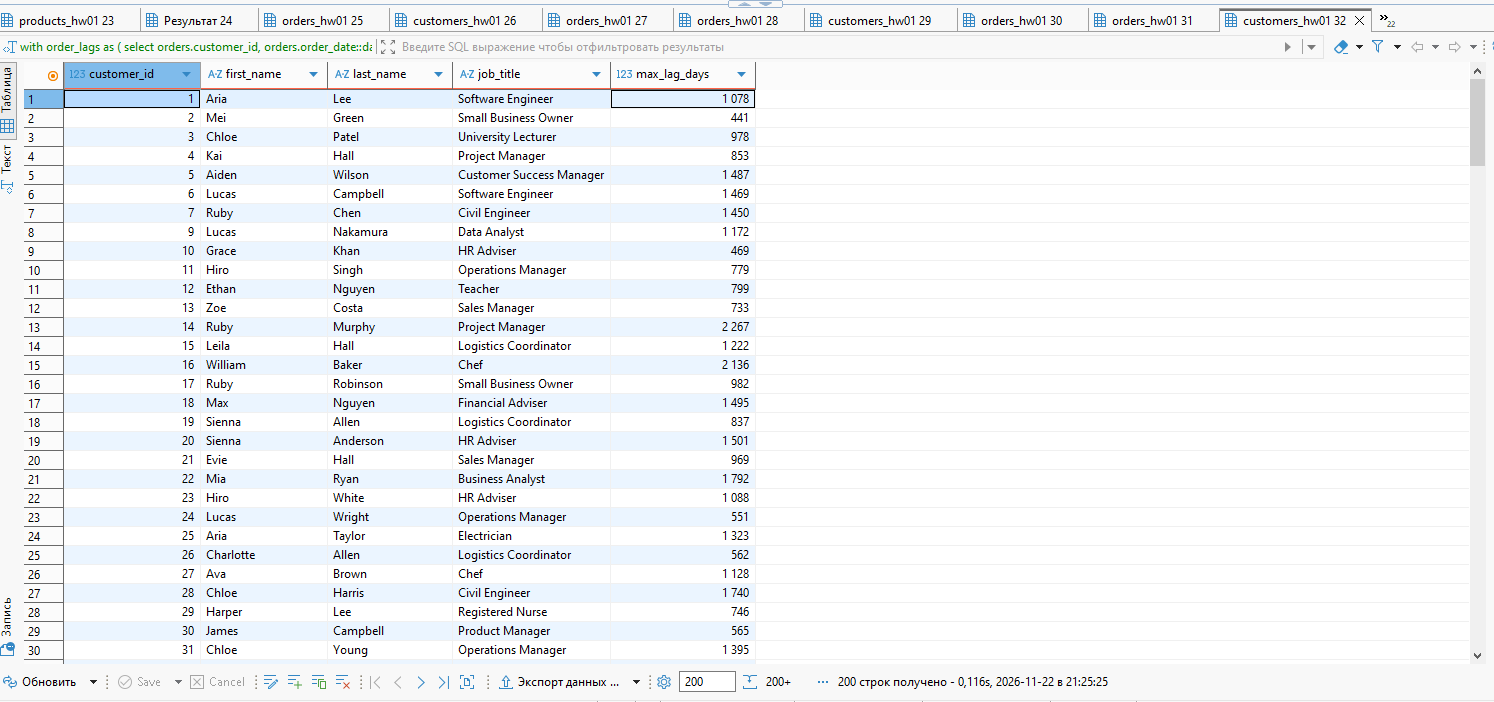

In [ ]:
Рефлексивная часть задания.

1.  Как вы думаете, зачем необходимо было выполнить это задание, и что у вас получилось?
'Выполнение задания было необходимо для осовоения базовых навыков работы с PostgreSQL.'
2.  Как выполняли: что сработало сразу, где застряли и как выбрались?
'Ранее не сталкивался с базами данных и PostgreSQL, поэтому каждое задание вызывало определнные трудности. В целом достаточно было обратиться к записям занятий и асинхронным материалам.'
3.  Если использовали ИИ, напишите цель, использованные промпты, где помощник ошибся и как вы это поняли. Если не использовали, так и напишите.
'Для выполнения задания использовал Алису в качестве автоматизированной справки по PostgreSQL и DBeaver'
4.  Что осталось непонятным (честный список, он поможет на консультации)?
'Не до конца понятна история с нормализацией исходных таблиц. Если по 1 и 2 группе нормализации таблицы проходят, то по 3 не ясно. В асинхронных материалах разница между 2 и 3 группами неочевидна'
5.  Самооценка по критериям задания.
'Считаю это задание хорошим опытом при знакомстве с базами данных, PostgreSQL и DBeaver.'
6.  Обратная связь по заданию. Что было ценно, что сложно, а что, на ваш взгляд, требует доработки?
'В некоторых задания не всегда было до конца понятно, что требуется. Например, в первом задании не до конца ясно, item_list_price_at_sale - это уже средняя цена, или надо взять среднюю item_list_price_at_sale по таблице. В задании 9 не понятно, что брать за категорию, класс или линейку. В задании 2 также не понятно, нужно рассчитать общую стоимость заказов по бренду, или надо рассчитать стоимость конкретного бренда в каждом заказе.'